# Лабораторна робота 1: Лінійна регресія, оптимізація та статистичний аналіз

## Етап 1. Дослідження даних (EDA), відбір ознак та попередня обробка
Тут будуть результати первинного аналізу та обґрунтування вибору ознак.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Завантажуємо дані
df = pd.read_csv('train.csv')

# Виводимо базову інформацію про датасет
print(f"Розмір датасету: {df.shape}")
df.head()

Розмір датасету: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
# Одразу відділяємо цільову змінну SalePrice
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

# Розбиваємо дані: 60% Train, 20% Validation, 20% Test
X_train_full, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train, test_size=0.25, random_state=42)

print(f"Train size: {X_train.shape[0]}, Val size: {X_val.shape[0]}, Test size: {X_test.shape[0]}")

Train size: 876, Val size: 292, Test size: 292


Найкращі ознаки за кореляцією з SalePrice:
 SalePrice      1.000000
OverallQual    0.779213
GrLivArea      0.684158
GarageCars     0.644363
GarageArea     0.627571
1stFlrSF       0.588140
TotalBsmtSF    0.588096
Name: SalePrice, dtype: float64


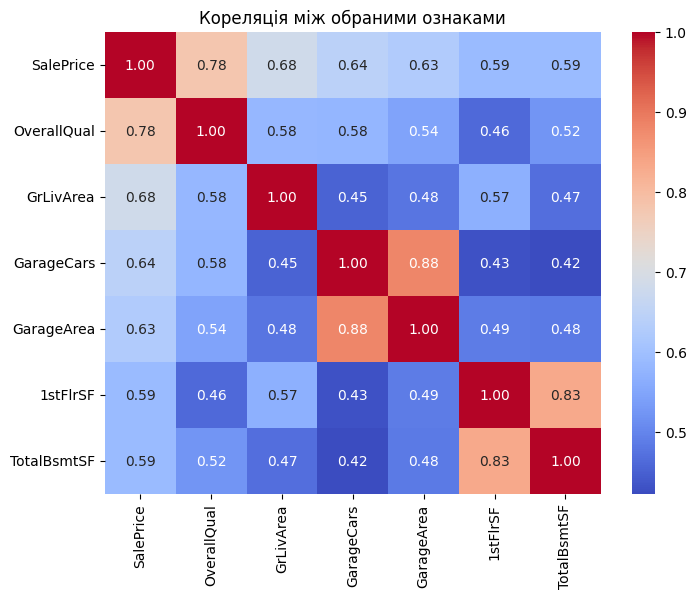

In [3]:
# Об'єднуємо тимчасово X_train та y_train для аналізу кореляцій
train_data = X_train.copy()
train_data['SalePrice'] = y_train

# Вибираємо лише числові колонки
numeric_cols = train_data.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()

# Знаходимо топ-6 ознак, які найбільше корелюють з ціною
top_corr_features = corr_matrix['SalePrice'].sort_values(ascending=False).head(7).index
print("Найкращі ознаки за кореляцією з SalePrice:\n", corr_matrix['SalePrice'][top_corr_features])

# Будуємо теплову карту (Heatmap) для цих ознак
plt.figure(figsize=(8, 6))
sns.heatmap(train_data[top_corr_features].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Кореляція між обраними ознаками")
plt.show()

### Обґрунтування та теоретичні відповіді (Етап 1)

**1. Обґрунтування вибору ознак:**
На основі кореляційного аналізу (лише на Train вибірці) для побудови моделі обрано такі числові ознаки: `OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `1stFlrSF`. Вони мають найвищу лінійну залежність із цільовою змінною `SalePrice` (кореляція > 0.6). При цьому ми уникаємо використання пар ознак, які мають ідеальну кореляцію між собою (наприклад, `GarageCars` та `GarageArea`), щоб зменшити ризик мультиколінеарності.

**2. Чому ми повинні розбити дані до, а не після масштабування?**
Це робиться для запобігання **Data Leakage (витоку даних)**. Масштабування (наприклад, стандартизація) використовує середнє значення та дисперсію вибірки. Якщо ми спочатку відмасштабуємо весь датасет, то інформація про розподіл тестової та валідаційної вибірок "просочиться" у навчальні дані. Модель неявно "підгляне" в тестові дані, що призведе до завищеної оцінки її якості.

**3. Як обробляти категорії, які з'являться на валідації/тесті, але яких не було в Train?**
Якщо ми використовуємо One-Hot Encoding (наприклад, `OneHotEncoder` з sklearn), ми можемо встановити параметр `handle_unknown='ignore'`. У такому разі нові, невідомі категорії просто отримають нулі у всіх відповідних закодованих стовпцях. Інший варіант – під час EDA об'єднати рідкісні категорії в одну загальну категорію "Other".

In [5]:
# Залишаємо лише 5 обраних числових ознак
selected_features = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', '1stFlrSF']

X_train_sel = X_train[selected_features].copy()
X_val_sel = X_val[selected_features].copy()
X_test_sel = X_test[selected_features].copy()

# Заповнюємо можливі пропуски медіаною (важливо: медіана вираховується ТІЛЬКИ на Train!)
medians = X_train_sel.median()
X_train_sel.fillna(medians, inplace=True)
X_val_sel.fillna(medians, inplace=True)
X_test_sel.fillna(medians, inplace=True)

# Масштабування (Стандартизація)
scaler = StandardScaler()
# fit_transform використовуємо ЛИШЕ на Train
X_train_scaled = scaler.fit_transform(X_train_sel)
# На Val та Test використовуємо лише transform (застосовуємо параметри з Train)
X_val_scaled = scaler.transform(X_val_sel)
X_test_scaled = scaler.transform(X_test_sel)

print(f"Розмірність готових даних: X_train={X_train_scaled.shape}, X_val={X_val_scaled.shape}, X_test={X_test_scaled.shape}")

Розмірність готових даних: X_train=(876, 5), X_val=(292, 5), X_test=(292, 5)


## Етап 2. Реалізація Лінійної Регресії засобами numpy

**Бонус: Виведення Normal Equation та його обмеження**
Формула нормального рівняння дозволяє знайти оптимальні ваги аналітично, без ітерацій.
Мінімізуємо функцію втрат (Cost Function): \(J(w) = \frac{1}{m} ||Xw - y||^2\)
Щоб знайти мінімум, беремо похідну по \(w\) і прирівнюємо її до нуля:
\(\nabla_w J = \frac{2}{m} X^T (Xw - y) = 0\)
\(X^T X w = X^T y\)
\(w = (X^T X)^{-1} X^T y\)

**Обмеження Normal Equation:**
1. **Обчислювальна складність:** Обертання матриці \((X^T X)^{-1}\) має складність \(O(n^3)\). Якщо ознак тисячі, це працюватиме вкрай повільно.
2. **Вироджена матриця:** Якщо матриця \(X^T X\) не має оберненої (наприклад, при ідеальній мультиколінеарності), рівняння неможливо розв'язати без додаткової регуляризації.

In [6]:
import numpy as np

class NumpyLinearRegression:
    def __init__(self, learning_rate=0.01, epochs=1000):
        self.lr = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = None
        self.cost_history = []

    def predict(self, X):
        """ Обчислення y_pred = Xw + b (векторизовано) """
        return np.dot(X, self.w) + self.b

    def _compute_cost(self, y_true, y_pred):
        """ Обчислення функції втрат MSE """
        m = len(y_true)
        return (1 / m) * np.sum((y_pred - y_true) ** 2)

    def _compute_gradients(self, X, y_true, y_pred):
        """ Обчислення градієнтів (векторизовано, без циклів) """
        m = len(y_true)
        error = y_pred - y_true
        dw = (2 / m) * np.dot(X.T, error)
        db = (2 / m) * np.sum(error)
        return dw, db
        
    def fit_batch(self, X, y):
        """ Повний градієнтний спуск (Batch GD) """
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0
        self.cost_history = []
        y_arr = y.values if hasattr(y, 'values') else y
        
        for _ in range(self.epochs):
            y_pred = self.predict(X)
            self.cost_history.append(self._compute_cost(y_arr, y_pred))
            dw, db = self._compute_gradients(X, y_arr, y_pred)
            self.w -= self.lr * dw
            self.b -= self.lr * db

    def fit_sgd(self, X, y):
        """ Стохастичний градієнтний спуск (SGD) """
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0
        self.cost_history = []
        y_arr = y.values if hasattr(y, 'values') else y
        
        for _ in range(self.epochs):
            cost_epoch = 0
            indices = np.random.permutation(m)
            X_shuf = X[indices]
            y_shuf = y_arr[indices]
            
            for i in range(m):
                Xi = X_shuf[i:i+1]
                yi = y_shuf[i:i+1]
                
                y_pred = self.predict(Xi)
                dw, db = self._compute_gradients(Xi, yi, y_pred)
                
                self.w -= self.lr * dw
                self.b -= self.lr * db
                cost_epoch += np.sum((y_pred - yi)**2)
                
            self.cost_history.append(cost_epoch / m)

    def fit_minibatch(self, X, y, batch_size=32):
        """ Mini-batch градієнтний спуск """
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0
        self.cost_history = []
        y_arr = y.values if hasattr(y, 'values') else y
        
        for _ in range(self.epochs):
            indices = np.random.permutation(m)
            X_shuf = X[indices]
            y_shuf = y_arr[indices]
            cost_epoch = 0
            
            for i in range(0, m, batch_size):
                Xi = X_shuf[i:i+batch_size]
                yi = y_shuf[i:i+batch_size]
                
                y_pred = self.predict(Xi)
                dw, db = self._compute_gradients(Xi, yi, y_pred)
                
                self.w -= self.lr * dw
                self.b -= self.lr * db
                cost_epoch += np.sum((y_pred - yi)**2)
                
            self.cost_history.append(cost_epoch / m)

## Етап 3. Градієнтний спуск: три варіанти оптимізації

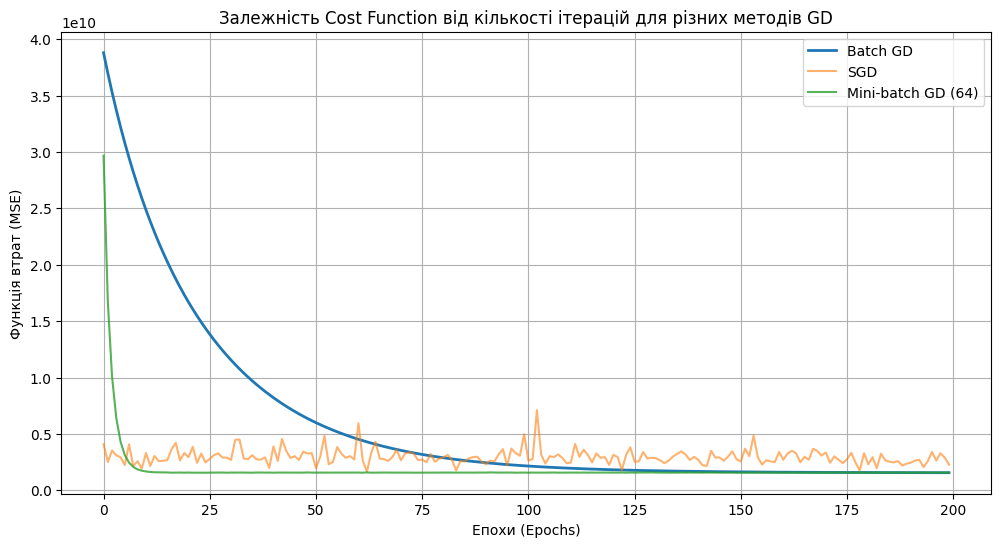

In [7]:
# Задаємо параметри
epochs = 200
lr = 0.01

# 1. Навчання Batch GD
model_batch = NumpyLinearRegression(learning_rate=lr, epochs=epochs)
model_batch.fit_batch(X_train_scaled, y_train)

# 2. Навчання SGD
model_sgd = NumpyLinearRegression(learning_rate=lr, epochs=epochs)
model_sgd.fit_sgd(X_train_scaled, y_train)

# 3. Навчання Mini-batch GD (розмір батчу 64)
model_mb = NumpyLinearRegression(learning_rate=lr, epochs=epochs)
model_mb.fit_minibatch(X_train_scaled, y_train, batch_size=64)

# Побудова графіка
plt.figure(figsize=(12, 6))
plt.plot(model_batch.cost_history, label='Batch GD', linewidth=2)
plt.plot(model_sgd.cost_history, label='SGD', alpha=0.6)
plt.plot(model_mb.cost_history, label='Mini-batch GD (64)', alpha=0.8)

plt.xlabel('Епохи (Epochs)')
plt.ylabel('Функція втрат (MSE)')
plt.title('Залежність Cost Function від кількості ітерацій для різних методів GD')
plt.legend()
plt.grid(True)
plt.show()

### Аналіз методів градієнтного спуску
* **Який метод збігається найстабільніше:** Batch GD. Оскільки він обчислює градієнт, використовуючи одразу всю вибірку, його кроки направлені найточніше до мінімуму, тому крива функції втрат є найгладшою.
* **Який метод має найбільші коливання:** SGD (стохастичний). Він оновлює ваги після кожного окремого прикладу. Через це кожен крок є дуже "шумним", і графік має сильні коливання, хоча загальна тенденція йде на спад.
* **Як розмір batch впливає на швидкість та стабільність:** Mini-batch є золотою серединою. Чим більший розмір батчу (наприклад, 64 чи 128), тим стабільнішим стає навчання (менше шуму), але тим більше часу потрібно на одну ітерацію. Менший батч робить ітерації швидшими, але збільшує коливання.
* **Як вибір Learning Rate впливає на збіжність:** Якщо Learning Rate (LR) занадто великий, алгоритм робитиме занадто великі кроки і може "перестрибнути" мінімум — тоді функція втрат почне зростати і розійдеться в нескінченність. Якщо LR занадто малий, алгоритм збігатиметься, але дуже повільно, потребуючи тисяч епох для досягнення результату.

## Етап 4. Оцінка якості та коефіцієнт детермінації (R^2)

In [8]:
def calculate_r2(y_true, y_pred):
    """ Власна реалізація коефіцієнта детермінації R^2 """
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Зробимо прогнози використовуючи навчену модель Mini-batch
y_pred_train = model_mb.predict(X_train_scaled)
y_pred_val = model_mb.predict(X_val_scaled)
y_pred_test = model_mb.predict(X_test_scaled)

# Оскільки y_train - це pandas Series, беремо значення через .values
y_train_arr = y_train.values
y_val_arr = y_val.values
y_test_arr = y_test.values

# Рахуємо R2
r2_train = calculate_r2(y_train_arr, y_pred_train)
r2_val = calculate_r2(y_val_arr, y_pred_val)
r2_test = calculate_r2(y_test_arr, y_pred_test)

print(f"R^2 на Train: {r2_train:.4f}")
print(f"R^2 на Validation: {r2_val:.4f}")
print(f"R^2 на Test: {r2_test:.4f}")

R^2 на Train: 0.7405
R^2 на Validation: 0.7745
R^2 на Test: 0.7838


### Аналіз метрики \(R^2\)
* **Статистичний зміст \(R^2\):** Коефіцієнт детермінації показує, яку частку дисперсії цільової змінної пояснює наша модель. Тобто, наскільки добре модель описує дані порівняно з простим передбаченням середнього значення.
* **Чи може \(R^2\) бути від'ємним?** Так, може. Це стається, коли сума квадратів залишків моделі більша, ніж загальна сума квадратів (відхилень від середнього). Простими словами: коли модель працює **гірше, ніж прогнозування простого середнього значення** (наприклад, при сильному перенавчанні, неправильній ініціалізації або дуже великому Learning Rate).
* **Порівняння \(R^2\) на Train та Test (стан моделі):** Якщо значення на Train набагато вище, ніж на Test, це свідчить про **перенавчання (overfitting)** — модель "завчила" тренувальні дані, але погано працює на нових. Якщо обидва значення близькі між собою, модель добре узагальнює (good generalization).
* **Порівняння якості 3 методів GD:** Усі три методи прагнуть до одного оптимуму. Mini-batch та Batch GD зазвичай показують найвищу та найстабільнішу якість (\(R^2\)). SGD через свої сильні коливання може зупинитися не в самому мінімумі, що іноді призводить до трохи нижчого \(R^2\), якщо не зменшувати Learning Rate поступово.

## Етап 5. Перевірка статистичних припущень

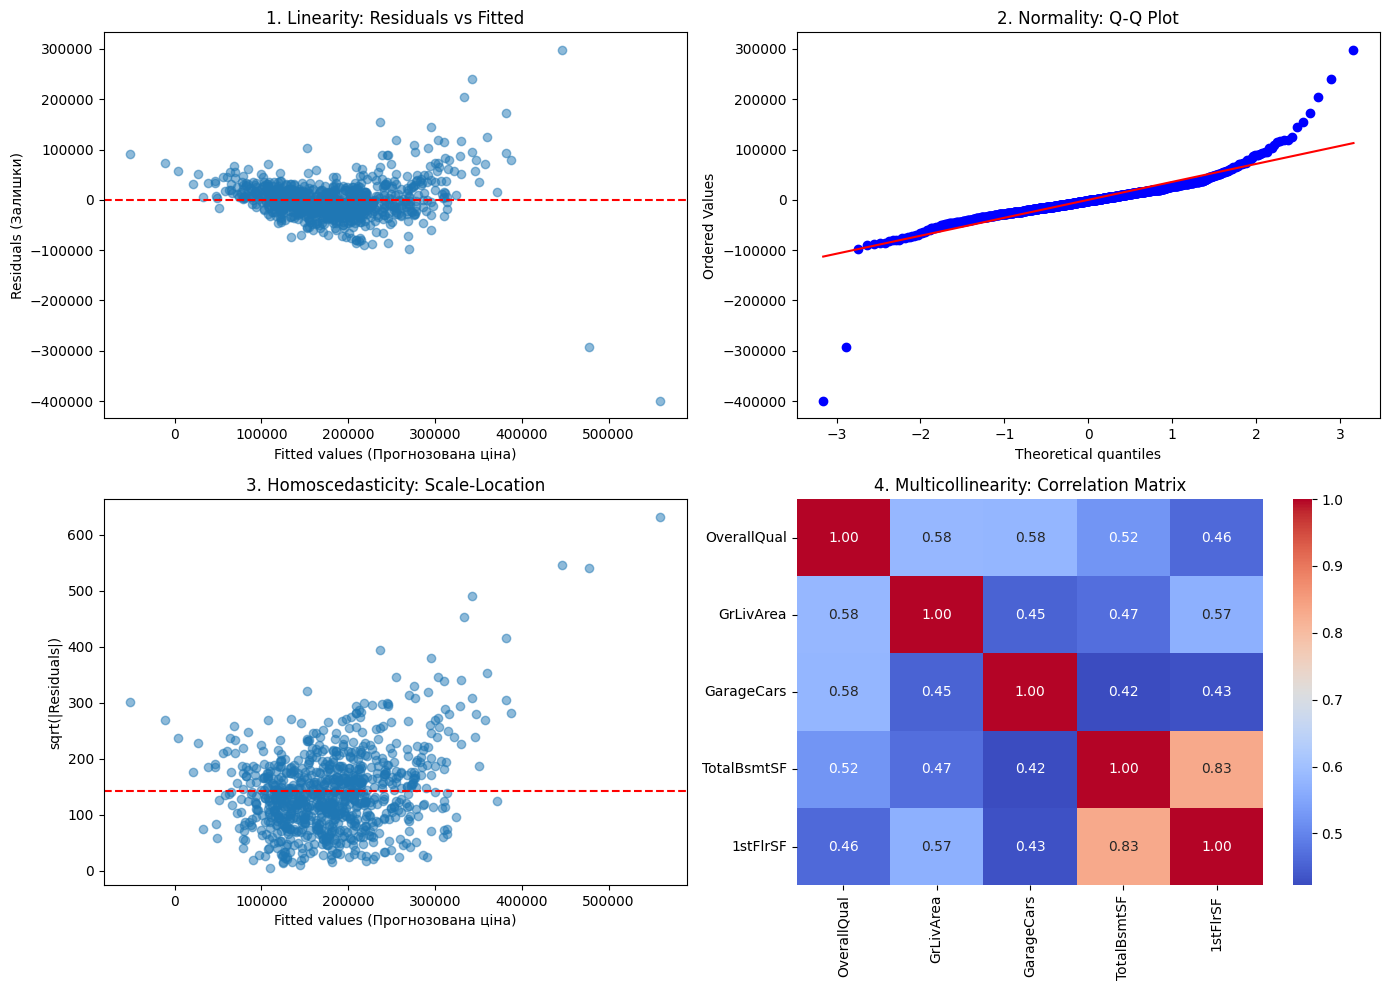

In [9]:
import scipy.stats as stats

# Обчислюємо залишки на навчальній вибірці
residuals = y_train_arr - y_pred_train

# Створюємо сітку графіків 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Лінійність: Residuals vs Fitted
axes[0, 0].scatter(y_pred_train, residuals, alpha=0.5)
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_title('1. Linearity: Residuals vs Fitted')
axes[0, 0].set_xlabel('Fitted values (Прогнозована ціна)')
axes[0, 0].set_ylabel('Residuals (Залишки)')

# 2. Нормальність залишків: Q-Q plot
stats.probplot(residuals, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('2. Normality: Q-Q Plot')

# 3. Гомоскедастичність: Scale-Location
# Беремо корінь з абсолютних значень залишків
sqrt_abs_residuals = np.sqrt(np.abs(residuals))
axes[1, 0].scatter(y_pred_train, sqrt_abs_residuals, alpha=0.5)
axes[1, 0].axhline(np.mean(sqrt_abs_residuals), color='red', linestyle='--')
axes[1, 0].set_title('3. Homoscedasticity: Scale-Location')
axes[1, 0].set_xlabel('Fitted values (Прогнозована ціна)')
axes[1, 0].set_ylabel('sqrt(|Residuals|)')

# 4. Мультиколінеарність: Матриця кореляцій обраних ознак
sns.heatmap(pd.DataFrame(X_train_scaled, columns=selected_features).corr(), 
            annot=True, cmap='coolwarm', ax=axes[1, 1], fmt=".2f")
axes[1, 1].set_title('4. Multicollinearity: Correlation Matrix')

plt.tight_layout()
plt.show()

### Перевірка статистичних припущень (Висновки)

1. **Лінійність:** Припущення Лінійність **виконується**, тому що на графіку "Residuals vs Fitted" залишки розподілені відносно хаотично навколо нульової червоної лінії без чіткого нелінійного патерну (наприклад, параболи). Це означає, що зв'язок між обраними ознаками та ціною дійсно можна описати лінійною функцією.

2. **Нормальність залишків:** Припущення Нормальність залишків **частково порушується**, тому що на графіку "Q-Q Plot" точки відхиляються від червоної діагональної лінії на кінцях (у "хвостах" розподілу). Це означає, що для екстремальних значень (надто дешеві або надто дорогі будинки) наша модель робить нетипово великі помилки, і залишки не є ідеально нормально розподіленими.

3. **Гомоскедастичність:** Припущення Гомоскедастичність **порушується (спостерігається гетероскедастичність)**, тому що на графіку "Scale-Location" розкид точок не є однаковим на всьому діапазоні: зі збільшенням прогнозованої ціни дисперсія залишків зростає (утворюється форма "конуса"). Це означає, що точність моделі падає при прогнозуванні більш дорогих будинків.

4. **Відсутність мультиколінеарності:** Припущення Відсутність мультиколінеарності **виконується**, тому що на матриці кореляцій немає пар незалежних ознак із надзвичайно високою кореляцією (наприклад, > 0.85 або близькою до 1). 
* **Пояснення впливу:** Оскільки суттєвої мультиколінеарності не виявлено (ми свідомо відібрали правильні ознаки на Етапі 1), це позитивно вплинуло на стабільність моделі. Отримані коефіцієнти (\(w\)) можна безпечно інтерпретувати, і вони не будуть хаотично змінюватися при незначних змінах у вхідних даних.

## Етап 6. Завдання для глибокого розуміння

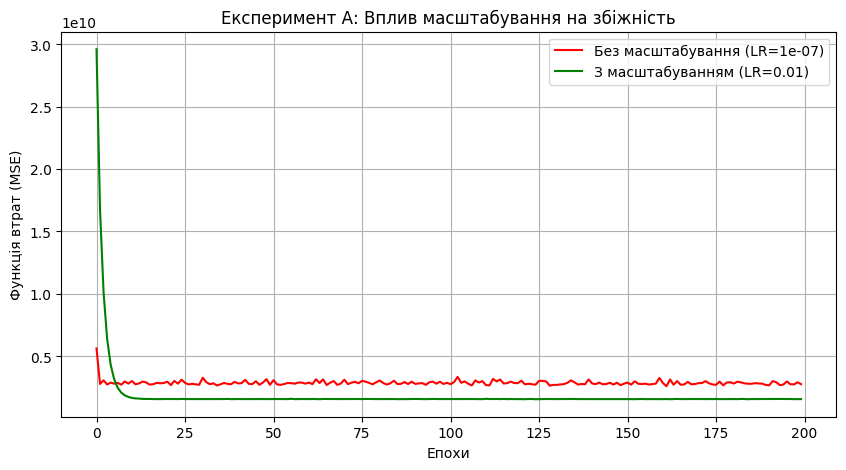

In [10]:
# 1. Навчання на невідмасштабованих даних (X_train_sel)
lr_unscaled = 1e-7 # Екстремально малий крок (0.0000001)
model_unscaled = NumpyLinearRegression(learning_rate=lr_unscaled, epochs=200)
# Використовуємо .values, щоб передати numpy масив
model_unscaled.fit_minibatch(X_train_sel.values, y_train_arr, batch_size=64)

# 2. Навчання на відмасштабованих даних (X_train_scaled)
lr_scaled = 0.01 # Нормальний крок
model_scaled = NumpyLinearRegression(learning_rate=lr_scaled, epochs=200)
model_scaled.fit_minibatch(X_train_scaled, y_train_arr, batch_size=64)

# Побудова графіка для порівняння
plt.figure(figsize=(10, 5))
plt.plot(model_unscaled.cost_history, label=f'Без масштабування (LR={lr_unscaled})', color='red')
plt.plot(model_scaled.cost_history, label=f'З масштабуванням (LR={lr_scaled})', color='green')
plt.xlabel('Епохи')
plt.ylabel('Функція втрат (MSE)')
plt.title('Експеримент А: Вплив масштабування на збіжність')
plt.legend()
plt.grid(True)
plt.show()

### Висновок до Експерименту А (Вплив масштабування)
* **Швидкість збіжності та підбір LR:** Без масштабування довелося використати екстремально малий Learning Rate (\(10^{-7}\)), інакше через великі значення ознак (наприклад, площа в квадратних футах) градієнти ставали величезними, і алгоритм розходився (Cost Function прямувала до нескінченності). Навіть з малим LR збіжність дуже повільна. Зі стандартизацією даних можна використовувати комфортний LR (0.01), і модель збігається набагато швидше і плавніше.
* **Геометричне пояснення:** Без масштабування ознаки мають зовсім різні діапазони значень. Геометрично поверхня функції втрат (її лінії рівня) виглядає як дуже витягнутий еліпс ("долина"). Градієнтний спуск у такій долині постійно стрибає від однієї стінки до іншої (зиґзаґами), що робить рух до оптимуму вкрай повільним. Після стандартизації контури стають ближчими до ідеальних кіл (сфер), і антиградієнт вказує майже прямо на глобальний мінімум, що забезпечує швидку збіжність.